# 01 – EDA: IBM AMLworld HI-Small

Load the cached transactions Parquet (`data/interim/hi_small_trans.parquet`) and take a first look.

In [1]:
print('Hello')

Hello


In [2]:
from pathlib import Path

import pandas as pd

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data' / 'interim' / 'hi_small_trans.parquet'
DATA

PosixPath('/Users/ravinderkumar/Work/upskill/AI/AIAgent/mule-detection/data/interim/hi_small_trans.parquet')

In [3]:
df = pd.read_parquet(DATA)
print(f'{df.shape[0]:,} rows x {df.shape[1]} cols')
df.head()

5,078,345 rows x 13 cols


,timestamp,from_bank,from_account,to_bank,to_account,amount_received,receiving_currency,amount_paid,payment_currency,payment_format,is_laundering,src,dst
0,2022-09-01 00:20:00,10,8000EBD30,10,8000EBD30,"3,697.34",US Dollar,"3,697.34",US Dollar,Reinvestment,0,10_8000EBD30,10_8000EBD30
1,2022-09-01 00:20:00,3208,8000F4580,1,8000F5340,0.01,US Dollar,0.01,US Dollar,Cheque,0,3208_8000F4580,1_8000F5340
2,2022-09-01 00:00:00,3209,8000F4670,3209,8000F4670,"14,675.57",US Dollar,"14,675.57",US Dollar,Reinvestment,0,3209_8000F4670,3209_8000F4670
3,2022-09-01 00:02:00,12,8000F5030,12,8000F5030,"2,806.97",US Dollar,"2,806.97",US Dollar,Reinvestment,0,12_8000F5030,12_8000F5030
4,2022-09-01 00:06:00,10,8000F5200,10,8000F5200,"36,682.97",US Dollar,"36,682.97",US Dollar,Reinvestment,0,10_8000F5200,10_8000F5200


In [4]:
df.info(memory_usage='deep')

<class 'pandas.DataFrame'>
RangeIndex: 5078345 entries, 0 to 5078344
Data columns (total 13 columns):
 #   Column              Dtype         
---  ------              -----         
 0   timestamp           datetime64[us]
 1   from_bank           int32         
 2   from_account        string        
 3   to_bank             int32         
 4   to_account          string        
 5   amount_received     float64       
 6   receiving_currency  str           
 7   amount_paid         float64       
 8   payment_currency    str           
 9   payment_format      str           
 10  is_laundering       int8          
 11  src                 str           
 12  dst                 str           
dtypes: datetime64[us](1), float64(2), int32(2), int8(1), str(5), string(2)
memory usage: 766.7 MB


## Data quality checks

### 1. Nulls

In [5]:
nulls = df.isna().sum().to_frame('nulls')
nulls['pct'] = nulls['nulls'] / len(df) * 100
nulls

,nulls,pct
timestamp,0,0.00
from_bank,0,0.00
from_account,0,0.00
to_bank,0,0.00
to_account,0,0.00
amount_received,0,0.00
receiving_currency,0,0.00
amount_paid,0,0.00
payment_currency,0,0.00
payment_format,0,0.00


### 2. Duplicates

In [6]:
feature_cols = [c for c in df.columns if c != 'is_laundering']

print('exact duplicate rows      :', df.duplicated().sum())
print('duplicates ignoring label :', df.duplicated(subset=feature_cols).sum())
print('self-transfers (src==dst)  :', (df['src'] == df['dst']).sum())
df[df.duplicated(keep=False)].sort_values(feature_cols).head(10)

exact duplicate rows      : 9
duplicates ignoring label : 9
self-transfers (src==dst)  : 591212


,timestamp,from_bank,from_account,to_bank,to_account,amount_received,receiving_currency,amount_paid,payment_currency,payment_format,is_laundering,src,dst
863294,2022-09-01 16:20:00,12004,800C927C1,220,813D8C1E1,0.00,Bitcoin,0.00,Bitcoin,Bitcoin,0,12004_800C927C1,220_813D8C1E1
863296,2022-09-01 16:20:00,12004,800C927C1,220,813D8C1E1,0.00,Bitcoin,0.00,Bitcoin,Bitcoin,0,12004_800C927C1,220_813D8C1E1
863293,2022-09-01 16:20:00,12004,800C927C1,12004,800C927C0,0.00,Bitcoin,0.08,Euro,ACH,0,12004_800C927C1,12004_800C927C0
863295,2022-09-01 16:20:00,12004,800C927C1,12004,800C927C0,0.00,Bitcoin,0.08,Euro,ACH,0,12004_800C927C1,12004_800C927C0
3684003,2022-09-07 21:25:00,29992,8099A29B1,220,813725AE1,0.00,Bitcoin,0.00,Bitcoin,Bitcoin,0,29992_8099A29B1,220_813725AE1
3684005,2022-09-07 21:25:00,29992,8099A29B1,220,813725AE1,0.00,Bitcoin,0.00,Bitcoin,Bitcoin,0,29992_8099A29B1,220_813725AE1
4166785,2022-09-08 21:05:00,113779,811144AB1,53744,813C777F1,0.00,Bitcoin,0.00,Bitcoin,Bitcoin,0,113779_811144AB1,53744_813C777F1
4166787,2022-09-08 21:05:00,113779,811144AB1,53744,813C777F1,0.00,Bitcoin,0.00,Bitcoin,Bitcoin,0,113779_811144AB1,53744_813C777F1
4166784,2022-09-08 21:05:00,113779,811144AB1,113779,811144AB0,0.00,Bitcoin,0.02,US Dollar,ACH,0,113779_811144AB1,113779_811144AB0
4166786,2022-09-08 21:05:00,113779,811144AB1,113779,811144AB0,0.00,Bitcoin,0.02,US Dollar,ACH,0,113779_811144AB1,113779_811144AB0


### 3. Dtypes and cardinality

In [7]:
summary = pd.DataFrame({'dtype': df.dtypes.astype(str), 'n_unique': df.nunique()})
summary

,dtype,n_unique
timestamp,datetime64[us],15018
from_bank,int32,30470
from_account,string,496995
to_bank,int32,15811
to_account,string,420636
amount_received,float64,915161
receiving_currency,str,15
amount_paid,float64,923873
payment_currency,str,15
payment_format,str,7


In [8]:
for c in ['receiving_currency', 'payment_currency', 'payment_format']:
    print(c, '->', sorted(df[c].unique()))
print()
df[['amount_received', 'amount_paid']].describe()

receiving_currency -> ['Australian Dollar', 'Bitcoin', 'Brazil Real', 'Canadian Dollar', 'Euro', 'Mexican Peso', 'Ruble', 'Rupee', 'Saudi Riyal', 'Shekel', 'Swiss Franc', 'UK Pound', 'US Dollar', 'Yen', 'Yuan']
payment_currency -> ['Australian Dollar', 'Bitcoin', 'Brazil Real', 'Canadian Dollar', 'Euro', 'Mexican Peso', 'Ruble', 'Rupee', 'Saudi Riyal', 'Shekel', 'Swiss Franc', 'UK Pound', 'US Dollar', 'Yen', 'Yuan']
payment_format -> ['ACH', 'Bitcoin', 'Cash', 'Cheque', 'Credit Card', 'Reinvestment', 'Wire']



,amount_received,amount_paid
count,"5,078,345.00","5,078,345.00"
mean,"5,988,726.07","4,509,273.37"
std,"1,037,183,108.89","869,772,830.92"
min,0.00,0.00
25%,183.37,184.48
50%,"1,411.01","1,414.54"
75%,"12,346.27","12,297.84"
max,"1,046,302,363,293.48","1,046,302,363,293.48"


In [9]:
print('non-positive amount_paid    :', (df['amount_paid'] <= 0).sum())
print('non-positive amount_received:', (df['amount_received'] <= 0).sum())

non-positive amount_paid    : 0
non-positive amount_received: 0


### 4. Timestamp range

In [10]:
ts = df['timestamp']
print('min     :', ts.min())
print('max     :', ts.max())
print('span    :', ts.max() - ts.min())
print('sorted  :', ts.is_monotonic_increasing)
print('days    :', ts.dt.normalize().nunique())

min     : 2022-09-01 00:00:00
max     : 2022-09-18 16:18:00
span    : 17 days 16:18:00
sorted  : False
days    : 18


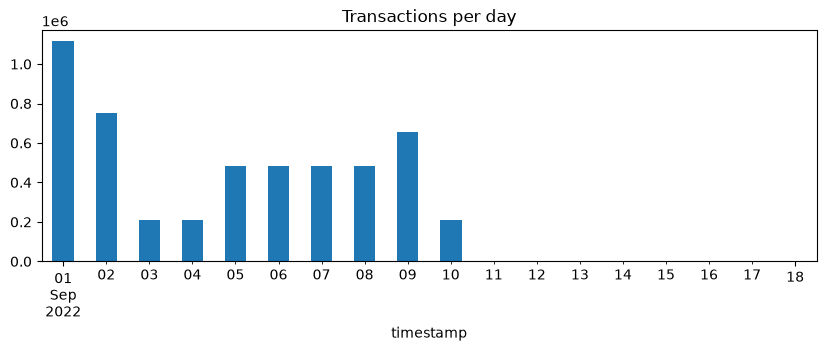

In [11]:
ts.dt.normalize().value_counts().sort_index().plot(kind='bar', figsize=(10, 3), title='Transactions per day');

## Class balance

                 count   pct
is_laundering               
legit          5073168 99.90
laundering        5177  0.10
imbalance ratio (legit : laundering) = 980 : 1


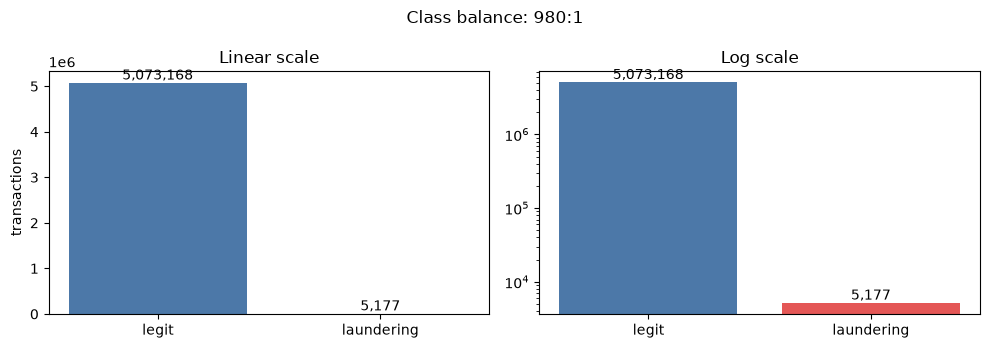

In [12]:
import matplotlib.pyplot as plt

counts = df['is_laundering'].value_counts().sort_index()
n_neg, n_pos = counts[0], counts[1]
ratio = n_neg / n_pos

print(counts.rename({0: 'legit', 1: 'laundering'}).to_frame('count').assign(pct=lambda d: d['count'] / d['count'].sum() * 100))
print(f'imbalance ratio (legit : laundering) = {ratio:,.0f} : 1')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
labels = ['legit', 'laundering']
colors = ['#4C78A8', '#E45756']

axes[0].bar(labels, counts.values, color=colors)
axes[0].set_title('Linear scale')
axes[0].set_ylabel('transactions')

axes[1].bar(labels, counts.values, color=colors)
axes[1].set_yscale('log')
axes[1].set_title('Log scale')

for ax in axes:
    for i, v in enumerate(counts.values):
        ax.text(i, v, f'{v:,}', ha='center', va='bottom')
fig.suptitle(f'Class balance: {ratio:,.0f}:1')
fig.tight_layout()

**Note:** laundering is a tiny minority class (~0.1%, roughly 1 in 980), so a model that predicts 'legit' for everything scores ~99.9% accuracy. Use PR-AUC / recall at a fixed precision rather than accuracy or ROC-AUC, and handle the imbalance with class weights or resampling (training split only) rather than assuming balanced data.

## Amount distributions: laundering vs legit

Amounts are in mixed currencies, so raw values are not strictly comparable across rows. `amount_paid` is shown in its own currency; a per-currency view follows.

In [16]:
import numpy as np

grp = df.groupby('is_laundering')['amount_paid']
stats = grp.describe(percentiles=[.01, .25, .5, .75, .99]).rename(index={0: 'legit', 1: 'laundering'})
stats.style.format('{:,.2f}')

,count,mean,std,min,1%,25%,50%,75%,99%,max
is_laundering,,,,,,,,,,
legit,"5,073,168.00","4,477,000.04","868,846,296.80",0.00,0.02,184.16,"1,410.99","12,279.34","13,515,035.01","1,046,302,363,293.48"
laundering,"5,177.00","36,135,310.41","1,527,918,669.80",0.00,1.00,"2,634.97","8,667.21","18,832.27","23,420,046.84","84,853,144,179.58"


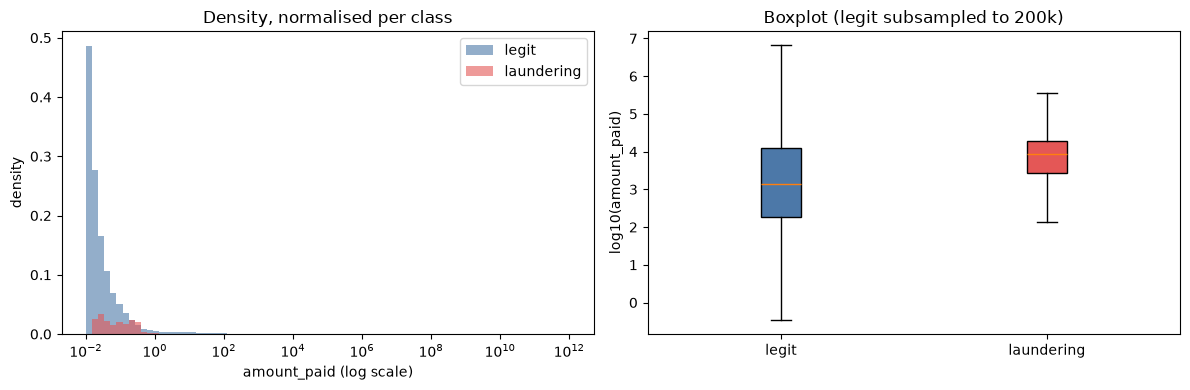

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.logspace(np.log10(df['amount_paid'].clip(lower=0.01).min()),
                   np.log10(df['amount_paid'].max()), 80)

for label, name, color in [(0, 'legit', '#4C78A8'), (1, 'laundering', '#E45756')]:
    x = df.loc[df['is_laundering'] == label, 'amount_paid']
    axes[0].hist(x, bins=bins, density=True, alpha=0.6, color=color, label=name)

axes[0].set_xscale('log')
axes[0].set_xlabel('amount_paid (log scale)')
axes[0].set_ylabel('density')
axes[0].set_title('Density, normalised per class')
axes[0].legend()

sample = pd.concat([
    df[df['is_laundering'] == 1],
    df[df['is_laundering'] == 0].sample(200_000, random_state=0),
])
sample['class'] = sample['is_laundering'].map({0: 'legit', 1: 'laundering'})
data = [np.log10(sample.loc[sample['class'] == c, 'amount_paid'].clip(lower=0.01)) for c in ['legit', 'laundering']]
bp = axes[1].boxplot(data, tick_labels=['legit', 'laundering'], patch_artist=True, showfliers=False)
for patch, color in zip(bp['boxes'], ['#4C78A8', '#E45756']):
    patch.set_facecolor(color)
axes[1].set_ylabel('log10(amount_paid)')
axes[1].set_title('Boxplot (legit subsampled to 200k)')
fig.tight_layout()

### Same view within the most common currency

Controls for the currency mix, so differences are not just an artefact of mixing currencies.

US Dollar 1,895,172 rows, 1,912 laundering


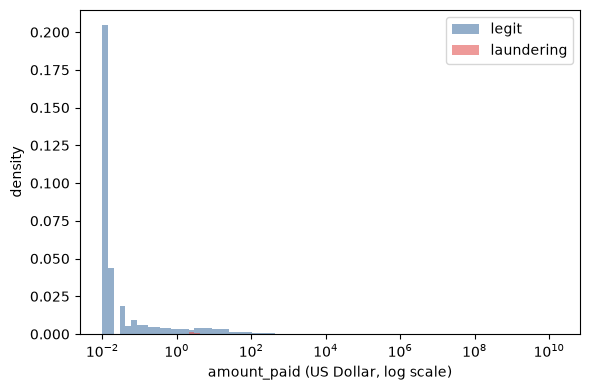

In [18]:
top_cur = df['payment_currency'].value_counts().index[0]
sub = df[df['payment_currency'] == top_cur]
print(top_cur, f'{len(sub):,} rows,', f"{sub['is_laundering'].sum():,} laundering")

fig, ax = plt.subplots(figsize=(6, 4))
bins = np.logspace(np.log10(sub['amount_paid'].clip(lower=0.01).min()), np.log10(sub['amount_paid'].max()), 80)
for label, name, color in [(0, 'legit', '#4C78A8'), (1, 'laundering', '#E45756')]:
    ax.hist(sub.loc[sub['is_laundering'] == label, 'amount_paid'], bins=bins, density=True, alpha=0.6, color=color, label=name)
ax.set_xscale('log')
ax.set_xlabel(f'amount_paid ({top_cur}, log scale)')
ax.set_ylabel('density')
ax.legend()
fig.tight_layout()

## Laundering rate by payment format

In [19]:
base_rate = df['is_laundering'].mean() * 100

fmt = (df.groupby('payment_format')['is_laundering']
         .agg(transactions='size', laundering='sum', rate_pct=lambda s: s.mean() * 100)
         .assign(share_of_all_laundering_pct=lambda d: d['laundering'] / d['laundering'].sum() * 100,
                 lift=lambda d: d['rate_pct'] / base_rate)
         .sort_values('rate_pct', ascending=False))
print(f'overall laundering rate: {base_rate:.3f}%')
fmt.style.format({'transactions': '{:,.0f}', 'laundering': '{:,.0f}', 'rate_pct': '{:.3f}',
                  'share_of_all_laundering_pct': '{:.1f}', 'lift': '{:.1f}x'})

overall laundering rate: 0.102%


,transactions,laundering,rate_pct,share_of_all_laundering_pct,lift
payment_format,,,,,
ACH,"600,797","4,483",0.746,86.6,7.3x
Bitcoin,"146,091",56,0.038,1.1,0.4x
Cash,"490,891",108,0.022,2.1,0.2x
Cheque,"1,864,331",324,0.017,6.3,0.2x
Credit Card,"1,323,324",206,0.016,4.0,0.2x
Reinvestment,"481,056",0,0.000,0.0,0.0x
Wire,"171,855",0,0.000,0.0,0.0x


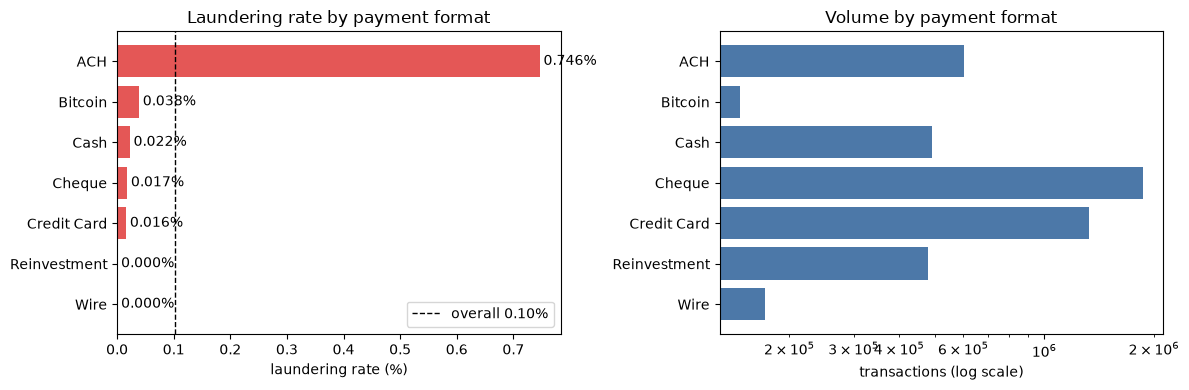

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].barh(fmt.index[::-1], fmt['rate_pct'][::-1], color='#E45756')
axes[0].axvline(base_rate, color='k', ls='--', lw=1, label=f'overall {base_rate:.2f}%')
axes[0].set_xlabel('laundering rate (%)')
axes[0].set_title('Laundering rate by payment format')
axes[0].legend()
for i, v in enumerate(fmt['rate_pct'][::-1]):
    axes[0].text(v, i, f' {v:.3f}%', va='center')

axes[1].barh(fmt.index[::-1], fmt['transactions'][::-1], color='#4C78A8')
axes[1].set_xscale('log')
axes[1].set_xlabel('transactions (log scale)')
axes[1].set_title('Volume by payment format')
fig.tight_layout()

## Laundering rate by currency, and cross-currency transfers

In [21]:
def rate_table(by):
    return (df.groupby(by)['is_laundering']
              .agg(transactions='size', laundering='sum', rate_pct=lambda s: s.mean() * 100)
              .assign(lift=lambda d: d['rate_pct'] / base_rate)
              .sort_values('rate_pct', ascending=False))

fmt_cols = {'transactions': '{:,.0f}', 'laundering': '{:,.0f}', 'rate_pct': '{:.3f}', 'lift': '{:.1f}x'}

print('By payment currency')
display(rate_table('payment_currency').style.format(fmt_cols))
print('By receiving currency')
display(rate_table('receiving_currency').style.format(fmt_cols))

By payment currency


,transactions,laundering,rate_pct,lift
payment_currency,,,,
Saudi Riyal,"89,014",374,0.420,4.1x
Euro,"1,168,297","1,372",0.117,1.2x
US Dollar,"1,895,172","1,912",0.101,1.0x
Yen,"155,209",155,0.100,1.0x
Australian Dollar,"136,769",127,0.093,0.9x
Canadian Dollar,"140,042",128,0.091,0.9x
Rupee,"190,202",167,0.088,0.9x
Yuan,"213,752",184,0.086,0.8x
Ruble,"155,178",133,0.086,0.8x


By receiving currency


,transactions,laundering,rate_pct,lift
receiving_currency,,,,
Saudi Riyal,"89,971",374,0.416,4.1x
Euro,"1,172,017","1,372",0.117,1.1x
US Dollar,"1,879,341","1,912",0.102,1.0x
Yen,"156,319",155,0.099,1.0x
Australian Dollar,"138,511",127,0.092,0.9x
Canadian Dollar,"141,357",128,0.091,0.9x
Yuan,"206,551",184,0.089,0.9x
Rupee,"192,065",167,0.087,0.9x
Ruble,"157,361",133,0.085,0.8x


In [22]:
# Flag: the sender pays in one currency and the receiver gets another
df['cross_currency'] = df['payment_currency'] != df['receiving_currency']

cc = rate_table('cross_currency')
cc.index = cc.index.map({False: 'same currency', True: 'cross-currency'})
print(f"cross-currency share of all transactions: {df['cross_currency'].mean() * 100:.2f}%")
cc.style.format(fmt_cols)

cross-currency share of all transactions: 1.42%


,transactions,laundering,rate_pct,lift
cross_currency,,,,
same currency,"5,006,175","5,177",0.103,1.0x
cross-currency,"72,170",0,0.000,0.0x


In [23]:
# Cross-currency by payment format: is it a currency effect or a format effect?
(df.groupby(['payment_format', 'cross_currency'])['is_laundering']
   .agg(transactions='size', laundering='sum', rate_pct=lambda s: s.mean() * 100)
   .style.format({'transactions': '{:,.0f}', 'laundering': '{:,.0f}', 'rate_pct': '{:.3f}'}))

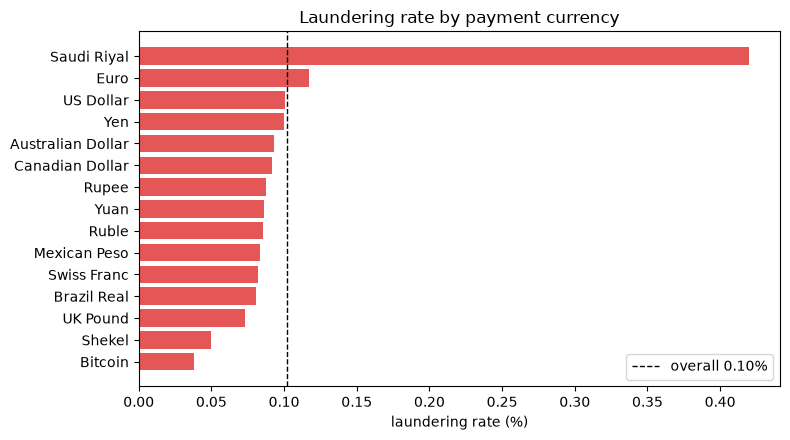

In [24]:
pc = rate_table('payment_currency')
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(pc.index[::-1], pc['rate_pct'][::-1], color='#E45756')
ax.axvline(base_rate, color='k', ls='--', lw=1, label=f'overall {base_rate:.2f}%')
ax.set_xlabel('laundering rate (%)')
ax.set_title('Laundering rate by payment currency')
ax.legend()
fig.tight_layout()

## Self-transfers

A self-transfer is a row where sender and receiver are the same node (`src == dst`, i.e. same bank *and* account). `from_account == to_account` alone would also match different accounts that share an ID at different banks, so it is shown only for comparison.

In [27]:
df['self_transfer'] = df['src'] == df['dst']
same_acct_id = df['from_account'] == df['to_account']

print(f"self-transfers (src == dst)           : {df['self_transfer'].sum():,} ({df['self_transfer'].mean() * 100:.2f}%)")
print(f"same account ID, any bank (comparison): {same_acct_id.sum():,}")

st = (df.groupby('self_transfer')['is_laundering']
        .agg(transactions='size', laundering='sum', rate_pct=lambda s: s.mean() * 100)
        .assign(lift=lambda d: d['rate_pct'] / base_rate))
st.index = st.index.map({False: 'different accounts', True: 'self-transfer'})
st.style.format({'transactions': '{:,.0f}', 'laundering': '{:,.0f}', 'rate_pct': '{:.3f}', 'lift': '{:.1f}x'})

self-transfers (src == dst)           : 591,212 (11.64%)
same account ID, any bank (comparison): 591,212


,transactions,laundering,rate_pct,lift
self_transfer,,,,
different accounts,"4,487,133","5,166",0.115,1.1x
self-transfer,"591,212",11,0.002,0.0x


In [28]:
# Which payment formats do self-transfers use?
(df[df['self_transfer']]
   .groupby('payment_format')['is_laundering']
   .agg(transactions='size', laundering='sum', rate_pct=lambda s: s.mean() * 100)
   .sort_values('transactions', ascending=False)
   .style.format({'transactions': '{:,.0f}', 'laundering': '{:,.0f}', 'rate_pct': '{:.3f}'}))

,transactions,laundering,rate_pct
payment_format,,,
Reinvestment,"481,056",0,0.000
ACH,"71,347",11,0.015
Bitcoin,"26,317",0,0.000
Cheque,"6,066",0,0.000
Credit Card,"4,176",0,0.000
Cash,"1,455",0,0.000
Wire,795,0,0.000


## Daily volume and laundering count

In [29]:
daily = (df.groupby(df['timestamp'].dt.normalize())['is_laundering']
           .agg(transactions='size', laundering='sum')
           .assign(rate_pct=lambda d: d['laundering'] / d['transactions'] * 100))
daily.index = daily.index.date
daily.style.format({'transactions': '{:,.0f}', 'laundering': '{:,.0f}', 'rate_pct': '{:.3f}'})

,transactions,laundering,rate_pct
2022-09-01,"1,114,921",322,0.029
2022-09-02,"754,449",408,0.054
2022-09-03,"207,382",391,0.189
2022-09-04,"207,430",407,0.196
2022-09-05,"482,650",471,0.098
2022-09-06,"482,089",531,0.110
2022-09-07,"482,751",497,0.103
2022-09-08,"482,773",539,0.112
2022-09-09,"654,467",514,0.079
2022-09-10,"208,325",442,0.212


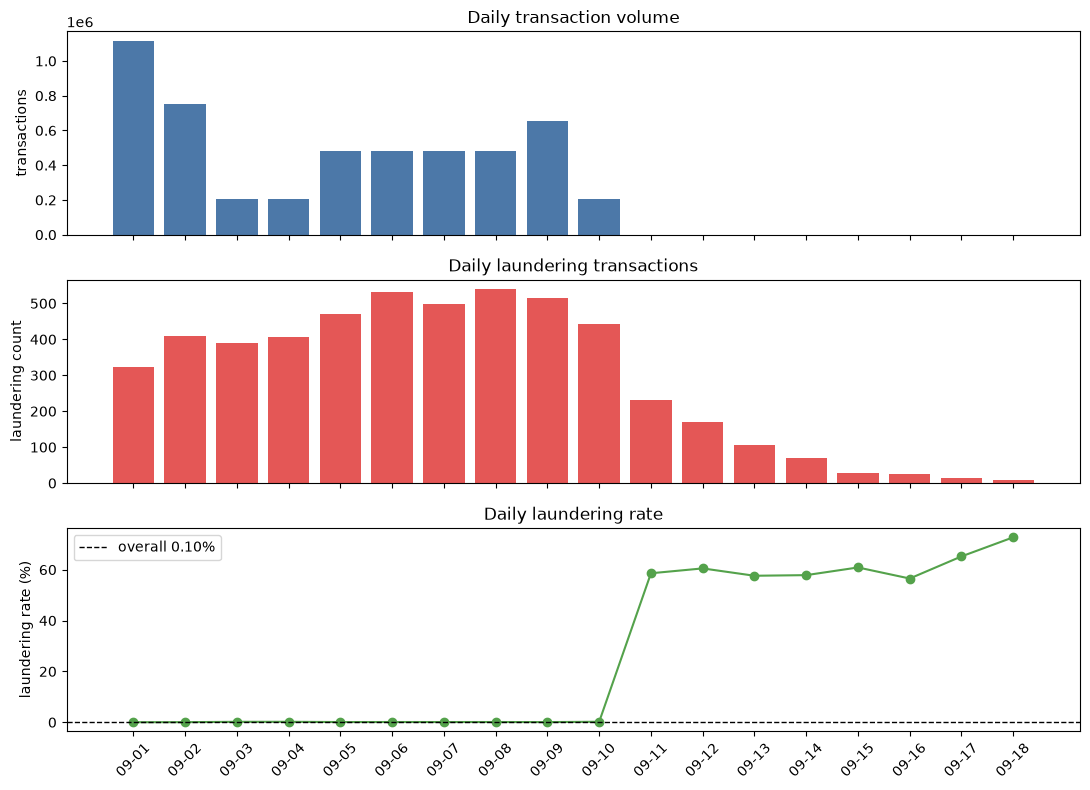

In [30]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
x = range(len(daily))

axes[0].bar(x, daily['transactions'], color='#4C78A8')
axes[0].set_ylabel('transactions')
axes[0].set_title('Daily transaction volume')

axes[1].bar(x, daily['laundering'], color='#E45756')
axes[1].set_ylabel('laundering count')
axes[1].set_title('Daily laundering transactions')

axes[2].plot(x, daily['rate_pct'], marker='o', color='#54A24B')
axes[2].axhline(base_rate, color='k', ls='--', lw=1, label=f'overall {base_rate:.2f}%')
axes[2].set_ylabel('laundering rate (%)')
axes[2].set_title('Daily laundering rate')
axes[2].legend()

axes[2].set_xticks(list(x))
axes[2].set_xticklabels([d.strftime('%m-%d') for d in daily.index], rotation=45)
fig.tight_layout()

**Note:** from 2022-09-11 onward the volume collapses (396 → 11 transactions/day) and the laundering rate jumps to ~58-73%. This looks like a generator artefact: background activity stops around 09-10 while laundering chains keep running. Anything after 09-10 is not representative of normal traffic. A time-based train/test split that puts these days in the test set will see an inflated positive rate, and a model could learn 'late date ⇒ laundering'. Consider excluding raw date/day-index features and deciding explicitly where these days go.

## Accounts

An account is identified by `src` / `dst` (bank + account ID). An account is *involved in laundering* if it appears on either side of at least one `is_laundering == 1` transaction.

In [33]:
all_acct = pd.concat([df['src'], df['dst']]).unique()
senders, receivers = df['src'].nunique(), df['dst'].nunique()

pos = df[df['is_laundering'] == 1]
pos_senders = pd.Index(pos['src'].unique())
pos_receivers = pd.Index(pos['dst'].unique())
pos_acct = pos_senders.union(pos_receivers)

n_all, n_pos = len(all_acct), len(pos_acct)
summary = pd.Series({
    'unique accounts': n_all,
    'unique senders': senders,
    'unique receivers': receivers,
    'accounts with >=1 laundering tx': n_pos,
    '  as sender': len(pos_senders),
    '  as receiver': len(pos_receivers),
    '  as both': len(pos_senders.intersection(pos_receivers)),
}, name='count').to_frame()
summary['pct_of_accounts'] = summary['count'] / n_all * 100
print(f'laundering accounts / all accounts: {n_pos / n_all * 100:.2f}%  (vs {base_rate:.2f}% of transactions)')
summary.style.format({'count': '{:,.0f}', 'pct_of_accounts': '{:.2f}'})

laundering accounts / all accounts: 1.23%  (vs 0.10% of transactions)


,count,pct_of_accounts
unique accounts,"515,088",100.00
unique senders,"496,999",96.49
unique receivers,"420,640",81.66
accounts with >=1 laundering tx,"6,357",1.23
as sender,"3,376",0.66
as receiver,"3,984",0.77
as both,"1,003",0.19


count   6,357.00
mean        1.63
std         4.49
min         1.00
25%         1.00
50%         1.00
75%         1.00
max       243.00

accounts where every transaction is laundering: 69 (1.1% of involved accounts)


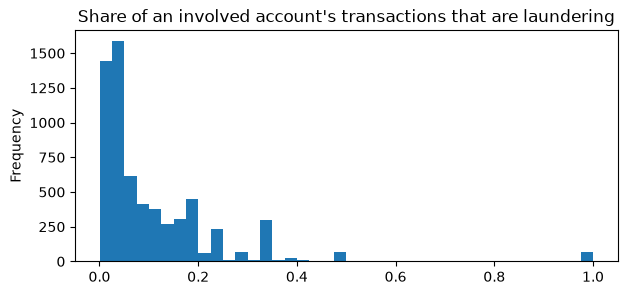

In [34]:
# How many laundering transactions does each involved account have, and what share of its activity is laundering?
acct_tx = pd.concat([df[['src', 'is_laundering']].rename(columns={'src': 'acct'}),
                     df[['dst', 'is_laundering']].rename(columns={'dst': 'acct'})])
per_acct = acct_tx.groupby('acct')['is_laundering'].agg(tx='size', laundering='sum')
involved = per_acct[per_acct['laundering'] > 0].assign(laundering_share=lambda d: d['laundering'] / d['tx'])

print(involved['laundering'].describe().round(2).to_string())
print()
print(f"accounts where every transaction is laundering: {(involved['laundering_share'] == 1).sum():,} "
      f"({(involved['laundering_share'] == 1).mean() * 100:.1f}% of involved accounts)")
involved['laundering_share'].plot(kind='hist', bins=40, figsize=(7, 3),
                                  title='Share of an involved account\'s transactions that are laundering');

## Key findings

1. **Clean but not tidy.** 5,078,345 transactions, no nulls, 9 exact duplicate rows, no non-positive amounts. Rows are not sorted by time, so sort before any time-based split or rolling feature.
2. **Extreme imbalance: ~980 : 1.** 5,177 laundering transactions (0.10%). Accuracy is meaningless; evaluate with PR-AUC / recall at fixed precision and apply class weights or resampling to the training split only.
3. **Payment format is the strongest signal.** ACH is 12% of transactions but 86.6% of all laundering (0.75% rate, 7.3x baseline). Reinvestment and Wire have zero laundering; Cash, Cheque, Credit Card and Bitcoin sit at 0.2-0.4x baseline.
4. **Laundering amounts are higher but overlap heavily.** Median `amount_paid` is ~8.7k for laundering vs ~1.4k for legit, and small payments (<~200) are almost all legit. The ranges overlap, so amount is a supporting feature, not a separator. Amounts are in mixed currencies; compare within a currency or normalise.
5. **Currency and cross-currency effects are small or artefacts.** Saudi Riyal stands out (0.42%, 4.1x) but may reflect specific banks rather than the currency. The 72,170 cross-currency transfers (1.4%, almost all ACH) contain zero laundering, which is a simulator property and not a real-world pattern. Self-transfers (11.6%, mostly Reinvestment) are almost never laundering (11 rows) and largely duplicate the payment-format signal.
6. **The last 8 days are a generator artefact.** After 2022-09-10 volume collapses (396 to 11 transactions/day) and the laundering rate jumps to ~58-73%, because laundering chains keep running after background traffic stops. These days hold 13% of all positives. Avoid raw date features and decide deliberately where they go in a temporal split.
7. **Account-level labels are less imbalanced.** 6,357 of 515,088 accounts (1.23%) touch a laundering transaction, about 12x the transaction-level rate (~80 : 1). Most involved accounts have a single laundering transaction, a few hubs have hundreds (max 243), and only 69 accounts are laundering-only, so involved accounts mix normal and illicit activity.
8. **Implications for modelling.** Several strong patterns (format, cross-currency, late dates) are likely generator artefacts, so a model may score well by exploiting them. Prefer account-level framing with graph and behavioural features, and validate that results hold when these shortcuts are removed.
